**A1: Vanishing point - Adriana Bujňáková**

**Použité obrázky:**
* chodba 1: https://unsplash.com/photos/long-hotel-hallway-with-red-carpet-and-wall-lamps-W4GKYkt4vqk
*   chodba2: https://unsplash.com/photos/brown-hallway-xx6oIX-SQKc
*   chodba 3: https://www.pexels.com/sk-sk/photo/chodba-vestibul-hala-prazdny-14840348/



---
---


**Koment k riešeniu:**

Začala som s parametrami Canny 100/200 a HoughLinesP s threshold=50, minLineLength=40 a maxLineGap=10.

Prvé fotky chodieb, ktoré som skúšala, mali vzorovanú podlahu (mramor, dlaždice,...). Po ekvalizácii a 45° maske sa vytvorilo množstvo krátkych čiar, centroidy K-means sa posunuli na podlahu a vanishing point vychádzal výrazne nižšie. Preto som obrázky nakoniec vymenila za iné chodby.

Ani na nových fotkách to s týmito parametrami nefungovalo všade. Dobre vyšla iba chodba 2, na chodbe 1 koberec stiahol vanishing point nadol a na chodbe 3 bodkovaný strop hore. Postupne som zväčšovala maxLineGap aj  minLineLength. Pri maxLineGap=40 sa už začal spájať aj šum z koberca, takže som skončila pri hodnotách minLineLength=80 a maxLineGap=30. Prahy Cannyho som nakoniec znížila na 50/150.

Skúšala som aj opačný prístup: vyššie prahy Cannyho a CLAHE namiesto equalizeHist. Hrany boli oveľa čistejšie, ale Hough našiel len pár desiatok čiar a jedna "zblúdená" čiara potom dostala vlastný zhluk, takže vanishing point vyšiel horšie.

Výstupy z Cannyho a Hougha síce nie sú pekné, je v nich veľa šumu, cez 800 čiar, no napriek tomu vanishing point vychádza na všetkých troch chodbách celkom blízko konca chodby a jeho y je blízko polovice výšky obrázka. Šum je rozložený približne symetricky, takže 4 centroidy skončia okolo stredu a ich priemer cca sedí.

| |  vanishing point na začiatku | vanishing point na konci - po úprave parametrov |
|---|---|---|
| chodba 1  | (258, 455) | (270, 407) |
| chodba 2  | (279, 390) | (310, 392) |
| chodba 3  | (221, 295) | (227, 355) |



---
---

**Použitie AI**

Použila som Claude (model Claude Opus 5.5) na: vysvetlenie nejasností v článku po jeho prečítaní a na úpravu kódu podľa môjho zadania. Pri skúšaní rôznych obrázkov som sa radila aj ohľadom mojich parametrov, prečo fungujú/nefungujú.

In [147]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

cv.setRNGSeed(0)   # aby kmeans dal pri kazdom spusteni rovnaky vysledok

**1. Načítanie a zmenšenie obrázkov**

In [148]:
img1 = cv.imread("/content/chodba1.jpg")
img2 = cv.imread("/content/chodba2.jpg")
img3 = cv.imread("/content/chodba3.jpg")

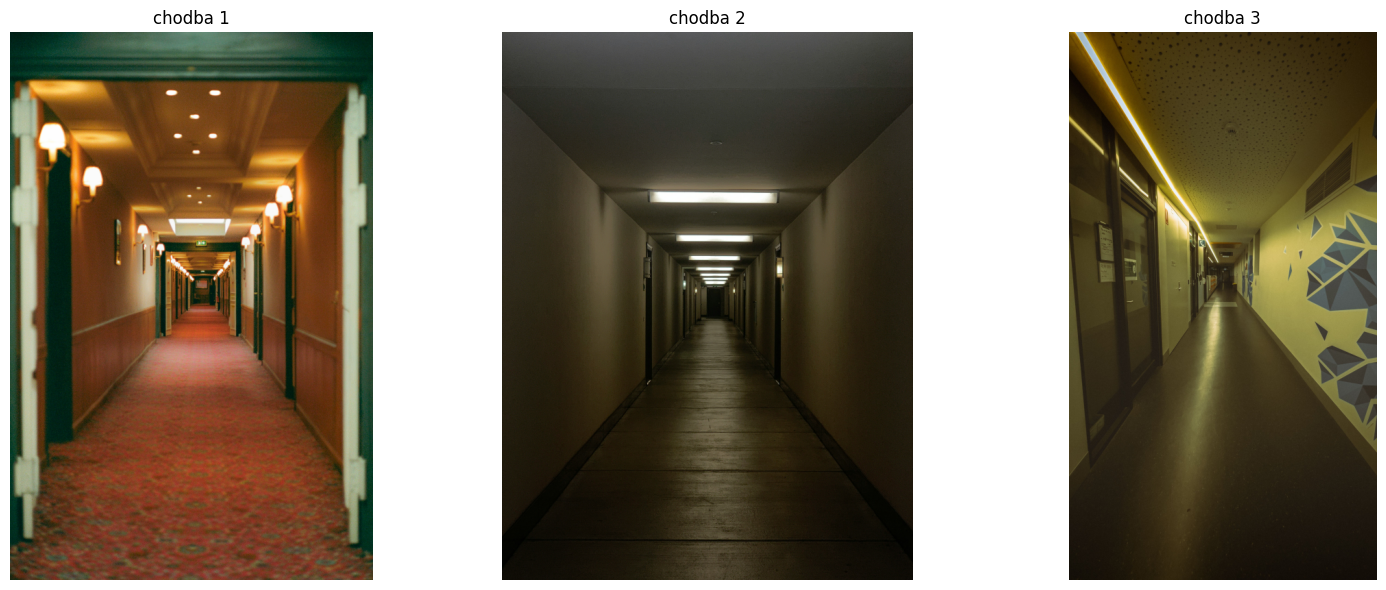

In [149]:
# fotky zmensim na vysku 800 px (sirku dopocitam podla pomeru stran)
def zmensi(img, vyska=800):
    h, w = img.shape[:2]
    skala = vyska / h
    return cv.resize(img, (int(w * skala), vyska), interpolation=cv.INTER_AREA)

obrazky = [zmensi(img1), zmensi(img2), zmensi(img3)]
nazvy = ["chodba 1", "chodba 2", "chodba 3"]

def zobraz(zoznam, titulky):
    fig, axes = plt.subplots(1, 3, figsize=(16, 6))
    for ax, im, t in zip(axes, zoznam, titulky):
        if im.ndim == 3:
            ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

zobraz(obrazky, nazvy)

**2.a 3. Šedotónový obrázok a ekvalizácia histogramu**

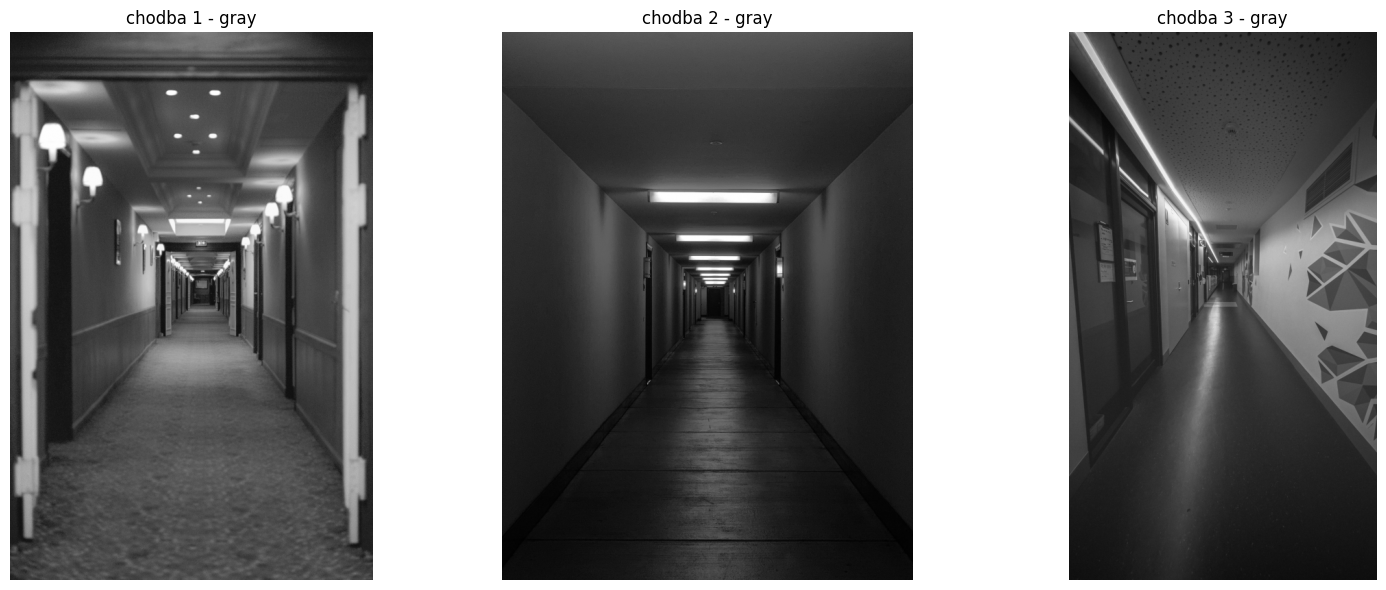

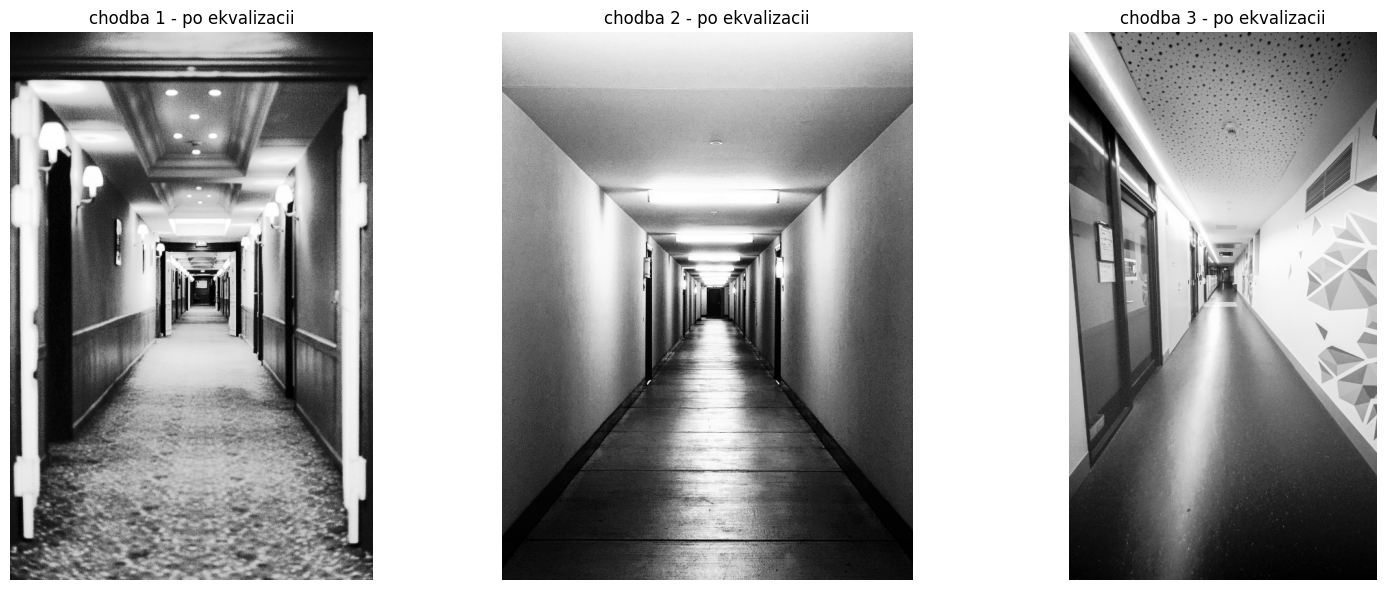

In [150]:
sede = [cv.cvtColor(img, cv.COLOR_BGR2GRAY) for img in obrazky]
ekvalizovane = [cv.equalizeHist(g) for g in sede]

zobraz(sede, [n + " - gray" for n in nazvy])
zobraz(ekvalizovane, [n + " - po ekvalizacii" for n in nazvy])

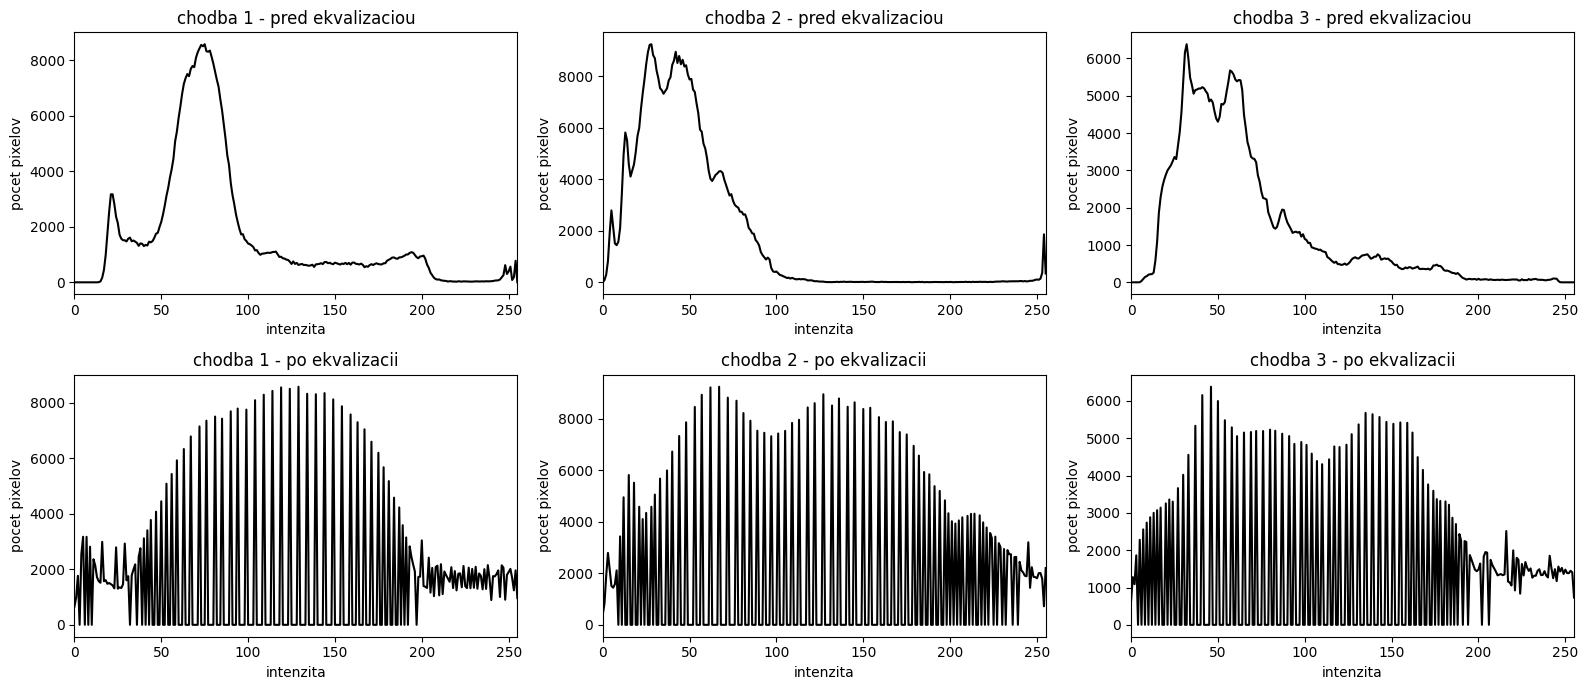

In [140]:
# histogramy pre kazdy obrazok, hore pred ekvalizaciou a dole po nej
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for i in range(3):
    for riadok, img, t in [(0, sede[i], "pred ekvalizaciou"), (1, ekvalizovane[i], "po ekvalizacii")]:
        hist = cv.calcHist([img], [0], None, [256], [0, 256])
        axes[riadok, i].plot(hist, color="black")
        axes[riadok, i].set_title(nazvy[i] + " - " + t)
        axes[riadok, i].set_xlim(0, 255)
        axes[riadok, i].set_xlabel("intenzita")
        axes[riadok, i].set_ylabel("pocet pixelov")
plt.tight_layout()
plt.show()

**4. Maska 45 stupňov**

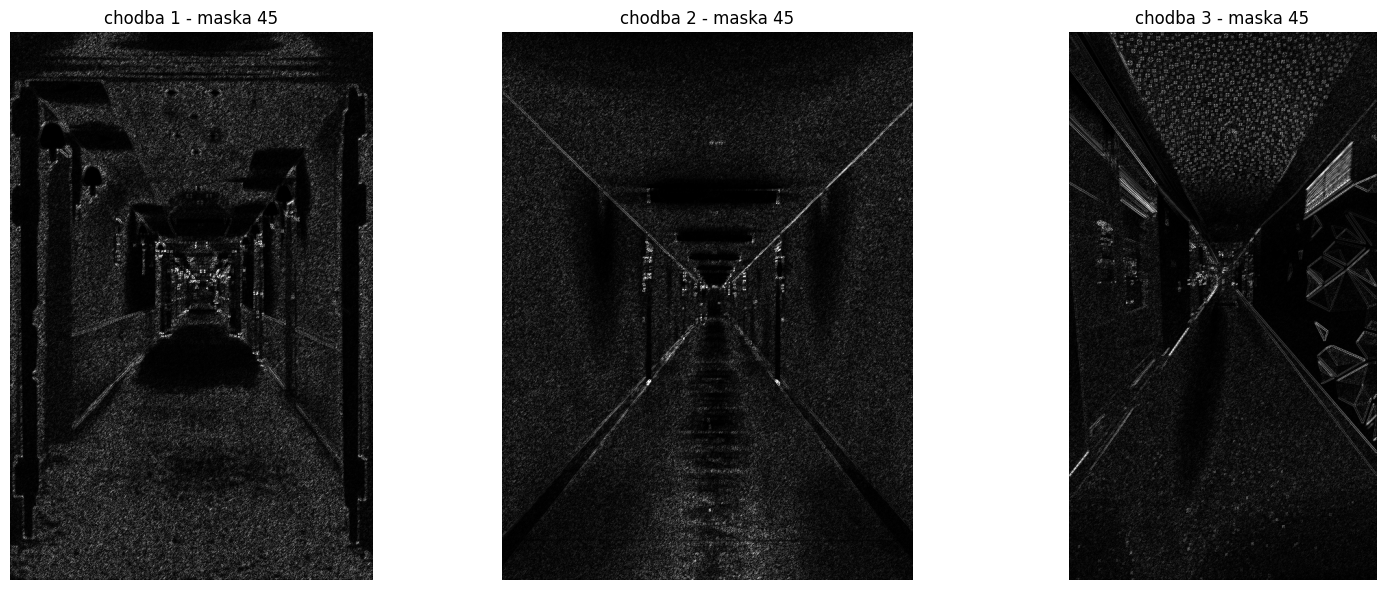

In [141]:
# maska z clanku
maska45 = np.array([[-1, -1,  2],
                    [-1,  2, -1],
                    [ 2, -1, -1]], dtype=np.float32)

# CV_32F kvoli zapornym hodnotam, convertScaleAbs to potom vrati do 0-255
filtrovane = [cv.convertScaleAbs(cv.filter2D(g, cv.CV_32F, maska45)) for g in ekvalizovane]
zobraz(filtrovane, [n + " - maska 45" for n in nazvy])

**5. Canny**

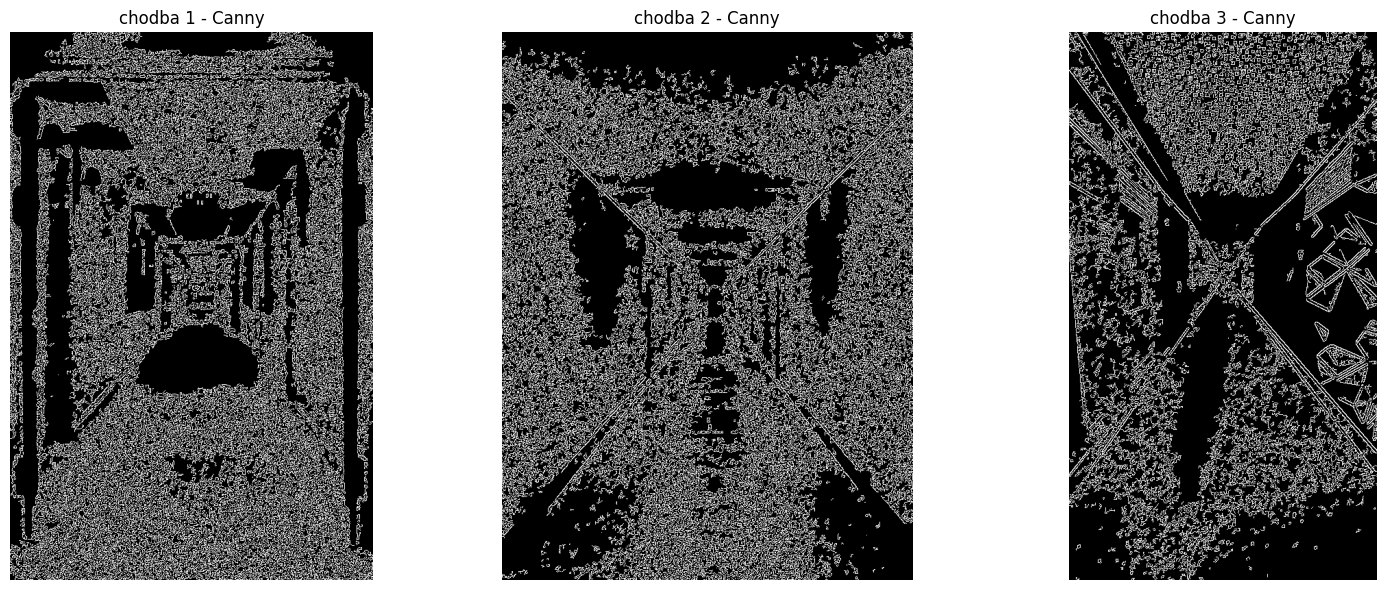

In [142]:
# prahy som skusala rozne, 50/150 fungovalo najlepsie (povodne napirklad 100/200 bolo horsie pri chodbe 1 a 3)
hrany = [cv.Canny(f, 50, 150) for f in filtrovane]

zobraz(hrany, [n + " - Canny" for n in nazvy])

**6. Hough transformácia**

In [143]:
minLineLength = 80
maxLineGap = 30
ciary = [cv.HoughLinesP(h, 1, np.pi / 180, 50, minLineLength=minLineLength, maxLineGap=maxLineGap) for h in hrany]

for n, c in zip(nazvy, ciary):
    print(n, "- pocet ciar:", len(c))

chodba 1 - pocet ciar: 872
chodba 2 - pocet ciar: 867
chodba 3 - pocet ciar: 824


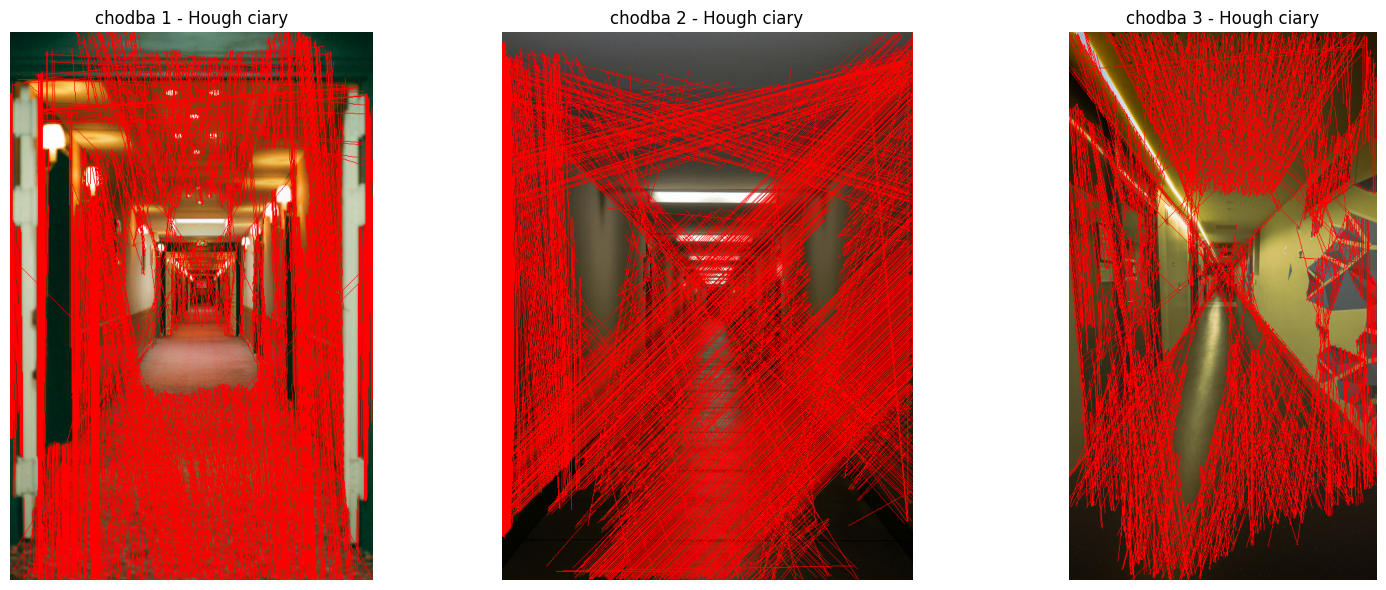

In [144]:
# vykreslenie najdenych ciar
s_ciarami = []
for img, c in zip(obrazky, ciary):
    kopia = img.copy()
    for x1, y1, x2, y2 in c.reshape(-1, 4):
        cv.line(kopia, (x1, y1), (x2, y2), (0, 0, 255), 1)
    s_ciarami.append(kopia)

zobraz(s_ciarami, [n + " - Hough ciary" for n in nazvy])

**7. K-means (k=4) na koncových bodoch čiar**

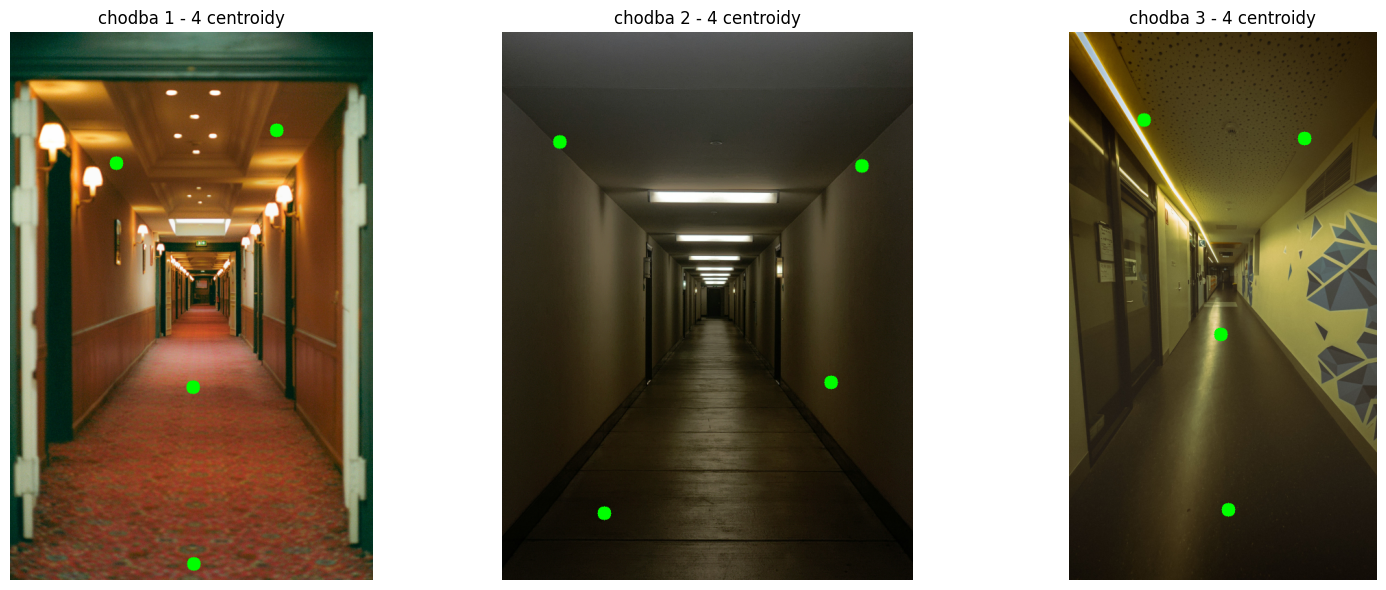

In [145]:
kriteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.2)

centroidy4 = []
for c in ciary:
  # kazda ciara da 2 body [x, y]
    body = c.reshape(-1, 2).astype(np.float32)
    _, _, centra = cv.kmeans(body, 4, None, kriteria, 10, cv.KMEANS_PP_CENTERS)
    centroidy4.append(centra)

s_centroidmi = []
for img, centra in zip(obrazky, centroidy4):
    kopia = img.copy()
    for x, y in centra:
        cv.circle(kopia, (int(x), int(y)), 10, (0, 255, 0), -1)
    s_centroidmi.append(kopia)

zobraz(s_centroidmi, [n + " - 4 centroidy" for n in nazvy])

**8. K-means (k=1) na 4 centroidoch = vanishing point**

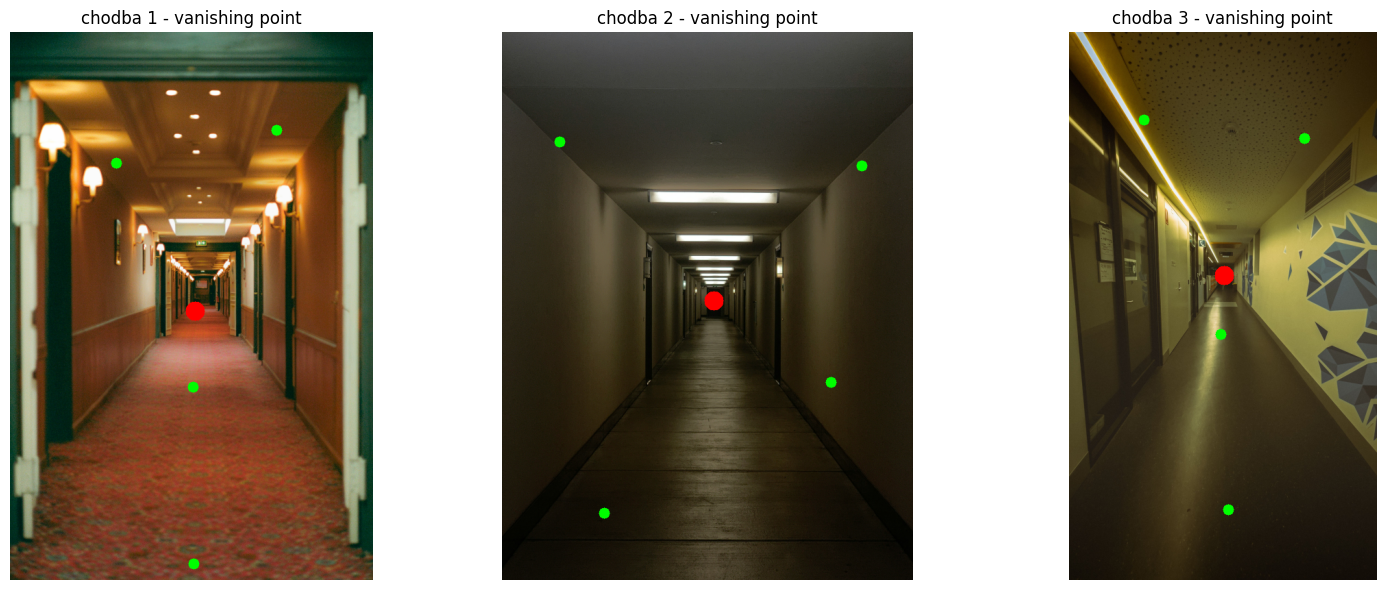

chodba 1: vanishing point = (270, 407), polovica vysky = 400
chodba 2: vanishing point = (310, 392), polovica vysky = 400
chodba 3: vanishing point = (227, 355), polovica vysky = 400


In [146]:
# k=1 - priemer tych 4 bodov
vanishing = []
for centra in centroidy4:
    _, _, vp = cv.kmeans(centra, 1, None, kriteria, 10, cv.KMEANS_PP_CENTERS)
    vanishing.append(vp[0])

# 4 centroidy (zelene) a vanishing point (cerveny)
vysledky = []
for img, centra, vp in zip(obrazky, centroidy4, vanishing):
    kopia = img.copy()
    for x, y in centra:
        cv.circle(kopia, (int(x), int(y)), 8, (0, 255, 0), -1)
    cv.circle(kopia, (int(vp[0]), int(vp[1])), 14, (0, 0, 255), -1)
    vysledky.append(kopia)

zobraz(vysledky, [n + " - vanishing point" for n in nazvy])

# y by malo byt blizko polovice vysky obrazka
for n, img, vp in zip(nazvy, obrazky, vanishing):
    print(f"{n}: vanishing point = ({vp[0]:.0f}, {vp[1]:.0f}), polovica vysky = {img.shape[0] / 2:.0f}")